In [22]:
import numpy as np
import scipy.sparse as sp
import gurobipy as gp
from gurobipy import GRB, quicksum
import discretizar_problema as disc
import mostrar_y_graficar_solucion as sol
import matplotlib.pyplot as plt
import data_generator as gen
import time
import random
import pandas as pd

In [3]:
diccionario_estados = dict()
diccionario_estados[2] = 'óptimo'
diccionario_estados[3] = 'infactible'
diccionario_estados[9] = 'tiempo agotado'
diccionario_estados[11] = 'interrumpido'

In [4]:
#sorteo instancias a usar de cada cantidad de grafos
todos_indices = [0,1,2,3,4]
random.seed(42)
ind_sorteados = random.sample(todos_indices,3) #son 0,2,4

In [5]:
discretizaciones = [11,21,5] #luego 21, si se llega también 5 (o 11 fil y 21 col)
lista_D = [1,2,3] #luego 2, y después 3
lista_G = [5,10]
lista_modelos = ['damero','completa 1','completa 2']

In [6]:
instances = gen.generar_instancias()

In [7]:
def separar(modelo):
    metrica = 0
    model = ''
    if modelo == 'damero':
        metrica = 1
        model = 'damero'
    if modelo == 'completa 2':
        metrica = 2
        model = 'completa'
    if modelo == 'completa 1':
        metrica = 1
        model = 'completa'
    return model, metrica

In [8]:
#construimos una lista de los casos a ejecutar, así podemos retomar desde el lugar correcto
#en caso de interrupciones. Voy a poner todos los casos, ya que ahora puedo cortar y retomar.
lista_casos = []
#hay 
for filas in discretizaciones:
    for D in lista_D:
        for modelo in lista_modelos:
            for G in lista_G:
                for indice in ind_sorteados:
                    lista_casos.append([filas,modelo,D,G,indice])
cantidad_casos = len(lista_casos)
len(lista_casos)

162

In [9]:
ultimo_caso_ejecutado = 139 #si hubo interrupción, este se cambia mirando el txt de casos ejecutados
ultimo_caso_a_ejecutar_mas_1 = 162 #se puede regular para no empezar a correr todo el resto de una
for j in range(ultimo_caso_ejecutado+1,ultimo_caso_a_ejecutar_mas_1):
    lista_valores = lista_casos[j]
    filas = lista_valores[0]
    modelo = lista_valores[1]
    D = lista_valores[2]
    G = lista_valores[3]
    indice = lista_valores[4]
    model, metrica = separar(modelo)
    m, tiempo_construccion, Z, M, L = disc.modelar_instancia(instances[(indice,G)].instances,model,metrica,N_D=60,filas=filas,columnas=filas,G=G,D=D)
    #me preparo para la eventualidad de no poder construir algún modelo a tiempo
    if tiempo_construccion < 1800: #queda tiempo para resolver
        #Introducimos estos cambios para cuidar la memoria desde el caso 81
        m.setParam('NodeFileDir', "C:\gurobi1203")
        #m.setParam('SoftMemLimit', 3)       # 10 GB hard limit
        #m.setParam('NodeFileStart', 0.05)     # Write to disk at 50MB

        # ===== METHOD =====
        #m.setParam('Method', 1)               # Dual simplex for root
        #m.setParam('NodeMethod', 1)           # Dual simplex for nodes
        m.optimize()
        f = open('resultados_experimentales.txt','a')
        #f.write('ind_instancia; G; D; filas; columnas; modelo; estado_solucion; cota_inf; cota_sup; gap; factibles_halladas; t_construccion; t_ejecucion; iterCount; nodos_explorados\n')
        f.write(str(indice)+'; '+str(G)+'; '+str(D)+'; '+str(filas)+'; '+str(filas)+'; '+modelo+'; '+diccionario_estados[m.Status]+'; '+str(m.ObjBound)+'; '+str(m.ObjVal)+'; '+str(m.MIPGap)+'; '+str(m.SolCount)+'; '+str(tiempo_construccion)+'; '+str(m.RunTime)+'; '+str(m.IterCount)+'; '+str(m.NodeCount)+'\n')
        f.close()
    else:
        f = open('resultados_experimentales.txt','a')
        #f.write('ind_instancia; G; D; filas; columnas; modelo; estado_solucion; cota_inf; cota_sup; gap; factibles_halladas; t_construccion; t_ejecucion; iterCount; nodos_explorados\n')
        f.write(str(indice)+'; '+str(G)+'; '+str(D)+'; '+str(filas)+'; '+str(filas)+'; '+modelo+'; '+'no construido'+'; '+str(-1)+'; '+str(-1)+'; '+str(-1)+'; '+str(m.SolCount)+'; '+str(tiempo_construccion)+'; '+str(m.RunTime)+'; '+str(-1)+'; '+str(-1)+'\n')
        f.close()
    m.dispose() #para liberar el espacio de memoria utilizado
    ultimo_caso_ejecutado += 1
    g = open('casos_ejecutados.txt','a')
    #g.write('ultimo_indice_ejecutado; discretizacion; modelo; D; G; indice\n')
    g.write(str(ultimo_caso_ejecutado)+'; '+str(filas)+'x'+str(filas)+'; '+modelo+'; '+str(D)+'; '+str(G)+'; '+str(indice)+'\n')
    g.close()

Set parameter Username
Set parameter LicenseID to value 2697574
Academic license - for non-commercial use only - expires 2026-08-21
Set parameter TimeLimit to value 1.7943007912635803e+03
Set parameter NodefileDir to value "C:\gurobi1203"
Gurobi Optimizer version 11.0.3 build v11.0.3rc0 (win64 - Windows 10.0 (19045.2))

CPU model: Intel(R) Core(TM) M-5Y10c CPU @ 0.80GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 2 physical cores, 4 logical processors, using up to 4 threads

Optimize a model with 3743 rows, 29830 columns and 148898 nonzeros
Model fingerprint: 0xd7828f9d
Variable types: 10 continuous, 29820 integer (29810 binary)
Coefficient statistics:
  Matrix range     [8e-01, 1e+02]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+02]
Presolve removed 740 rows and 3489 columns
Presolve time: 1.02s
Presolved: 3003 rows, 26341 columns, 111207 nonzeros
Variable types: 15 continuous, 26326 integer (26322 binary)
Deterministic concurren

In [6]:
f = open('resultados_experimentales.txt','r')
lista_renglones = f.readlines()
lista_renglones_sin_espacios = []
for linea in lista_renglones:
    linea_nueva = linea.replace(" ","")
    linea_nueva = linea_nueva.replace(";",",")
    lista_renglones_sin_espacios.append(linea_nueva)
f.close()
#g = open('resultados_a_csv.txt','w')
#g.write()
g = open('resultados_a_csv.txt','w')
g.write(lista_renglones_sin_espacios[0])
g.close()
g = open('resultados_a_csv.txt','a')
for linea_nueva in lista_renglones_sin_espacios[1:]:
    g.write(linea_nueva)
g.close()

In [33]:
lista_columnas = lista_renglones_sin_espacios[0].replace('\n','').split(',')
lista_filas = []
for linea in lista_renglones_sin_espacios[1:]:
    lista_filas.append(linea.replace('\n','').split(','))
df_resultados = pd.DataFrame(lista_filas,columns = lista_columnas)
df_resultados

,ind_instancia,G,D,filas,columnas,modelo,estado_solucion,cota_inf,cota_sup,gap,factibles_halladas,t_construccion(s),t_ejecucion(s),iteraciones,nodos_explorados
0,0,5,1,11,11,damero,óptimo,148.22773321217403,148.22773321217403,0.0,10,25.50756287574768,911.8759999275208,894978.0,1706.0
1,4,5,1,11,11,damero,óptimo,140.23131462051646,140.23131462051646,0.0,10,31.791568756103516,588.9299998283386,343334.0,8414.0
2,2,5,1,11,11,damero,óptimo,181.94078336231973,181.94078336231976,0.0,10,33.789960622787476,1299.8959999084473,695344.0,4479.0
3,0,10,1,11,11,damero,tiempoagotado,227.50254703281038,269.447895365162,0.15567146395968814,10,70.21207022666931,1729.9630000591278,157945.0,1.0
4,4,10,1,11,11,damero,tiempoagotado,240.24021544616966,inf,inf,0,57.8623731136322,1742.4260001182556,242989.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
157,4,5,3,5,5,completa2,óptimo,72.72560577274804,72.72560577274804,0.0,10,5.984377145767212,920.8019998073578,2226337.0,3404.0
158,2,5,3,5,5,completa2,tiempoagotado,64.82271959572836,108.89042440154003,0.40469770457785476,10,6.468774318695068,1793.619000196457,2434595.0,1319.0
159,0,10,3,5,5,completa2,tiempoagotado,77.31973052738489,169.21358055153706,0.5430642725284348,7,24.098090410232544,1776.1480000019073,1432830.0,120.0
160,4,10,3,5,5,completa2,tiempoagotado,79.44958439091748,253.32300597064943,0.6863704341163444,8,22.790868282318115,1777.401999950409,225843.0,1.0


In [34]:
atributos_numericos = ['ind_instancia','G','D','filas','columnas','factibles_halladas','iteraciones','nodos_explorados','cota_inf','cota_sup','gap','t_construccion(s)','t_ejecucion(s)']

In [37]:
def convertir_numericos(num_string):
    if num_string == 'inf':
        return np.inf
    else:
        return round(float(num_string),2)

In [38]:
for numerico in atributos_numericos:
    df_resultados[numerico] = df_resultados[numerico].apply(convertir_numericos)
df_resultados #columnas convertidas exitosamente

,ind_instancia,G,D,filas,columnas,modelo,estado_solucion,cota_inf,cota_sup,gap,factibles_halladas,t_construccion(s),t_ejecucion(s),iteraciones,nodos_explorados
0,0.0,5.0,1.0,11.0,11.0,damero,óptimo,148.23,148.23,0.00,10.0,25.51,911.88,894978.0,1706.0
1,4.0,5.0,1.0,11.0,11.0,damero,óptimo,140.23,140.23,0.00,10.0,31.79,588.93,343334.0,8414.0
2,2.0,5.0,1.0,11.0,11.0,damero,óptimo,181.94,181.94,0.00,10.0,33.79,1299.90,695344.0,4479.0
3,0.0,10.0,1.0,11.0,11.0,damero,tiempoagotado,227.50,269.45,0.16,10.0,70.21,1729.96,157945.0,1.0
4,4.0,10.0,1.0,11.0,11.0,damero,tiempoagotado,240.24,inf,inf,0.0,57.86,1742.43,242989.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
157,4.0,5.0,3.0,5.0,5.0,completa2,óptimo,72.73,72.73,0.00,10.0,5.98,920.80,2226337.0,3404.0
158,2.0,5.0,3.0,5.0,5.0,completa2,tiempoagotado,64.82,108.89,0.40,10.0,6.47,1793.62,2434595.0,1319.0
159,0.0,10.0,3.0,5.0,5.0,completa2,tiempoagotado,77.32,169.21,0.54,7.0,24.10,1776.15,1432830.0,120.0
160,4.0,10.0,3.0,5.0,5.0,completa2,tiempoagotado,79.45,253.32,0.69,8.0,22.79,1777.40,225843.0,1.0


In [40]:
df_resultados.to_excel('resultados_a_excel.xlsx')

In [23]:
#Ahora sacamos promedios
df_resultados = pd.read_excel('resultados_a_excel.xlsx')

In [24]:
df_resultados

,ind,G,D,disc,mod,estado,cota_inf,cota_sup,gap,fact,t_const(s),t_ejec(s),iter,nodos_expl
0,0,5,1,11x11,damero,óptimo,148.23,148.23,0.00,10,25.51,911.88,894978,1706
1,4,5,1,11x11,damero,óptimo,140.23,140.23,0.00,10,31.79,588.93,343334,8414
2,2,5,1,11x11,damero,óptimo,181.94,181.94,0.00,10,33.79,1299.90,695344,4479
3,0,10,1,11x11,damero,tiempoagotado,227.50,269.45,0.16,10,70.21,1729.96,157945,1
4,4,10,1,11x11,damero,tiempoagotado,240.24,inf,inf,0,57.86,1742.43,242989,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
157,4,5,3,5x5,completa2,óptimo,72.73,72.73,0.00,10,5.98,920.80,2226337,3404
158,2,5,3,5x5,completa2,tiempoagotado,64.82,108.89,0.40,10,6.47,1793.62,2434595,1319
159,0,10,3,5x5,completa2,tiempoagotado,77.32,169.21,0.54,7,24.10,1776.15,1432830,120
160,4,10,3,5x5,completa2,tiempoagotado,79.45,253.32,0.69,8,22.79,1777.40,225843,1


In [76]:
optimos = df_resultados[df_resultados['estado'] == 'óptimo']
optimos[['ind','G','D','disc','mod','iter','nodos_expl']]

,ind,G,D,disc,mod,iter,nodos_expl
0,0,5,1,11x11,damero,894978,1706
1,4,5,1,11x11,damero,343334,8414
2,2,5,1,11x11,damero,695344,4479
19,4,5,2,11x11,damero,3538818,2650
108,0,5,1,5x5,damero,49841,967
109,4,5,1,5x5,damero,54294,309
110,2,5,1,5x5,damero,127753,786
114,0,5,1,5x5,completa1,72638,406
115,4,5,1,5x5,completa1,72159,539
116,2,5,1,5x5,completa1,244797,776


In [55]:
factibles = df_resultados[df_resultados['fact'] > 0]
fact_comp = factibles[factibles['mod'] != 'completa1']
fact_comp = fact_comp[['ind','G','D','disc','mod','gap','fact']]
#37 instancias para el damero, 28 para la completa
fact_damero = fact_comp[fact_comp['mod']=='damero']
fact_completa = fact_comp[fact_comp['mod']=='completa2']
prom_dam = fact_damero['fact'].mean()
prom_completa = fact_completa['gap'].mean()
len(fact_completa)

25

In [10]:
#promedios por cantidad de grafos
mods = ['damero','completa1','completa2']
for mod in mods:
    df_filtrado = df_resultados[df_resultados['mod'] == mod]
    print(mod)
    print(df_filtrado['t_const(s)'].mean())

damero
131.0261111111111
completa1
140.3918518518519
completa2
144.21425925925928


[Text(0, 0, '69.04'),
 Text(0, 0, '208.04'),
 Text(0, 0, '93.27'),
 Text(0, 0, '139.25'),
 Text(0, 0, '183.11'),
 Text(0, 0, '131.03'),
 Text(0, 0, '140.39'),
 Text(0, 0, '144.21')]

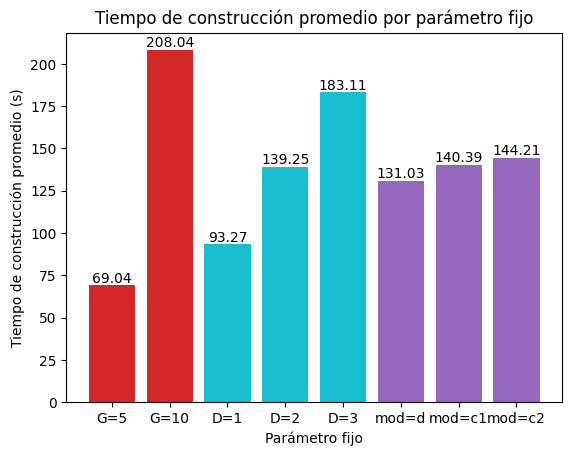

In [20]:
parametros = ['G=5','G=10','D=1','D=2','D=3','mod=d','mod=c1','mod=c2']
promedios = [69.04,208.04,93.27,139.25,183.11,131.03,140.39,144.21]
fig, ax = plt.subplots()
plt.xlabel('Parámetro fijo')
plt.ylabel('Tiempo de construcción promedio (s)')
ax.set_title('Tiempo de construcción promedio por parámetro fijo')
lista_colores = ['tab:red','tab:red','tab:cyan','tab:cyan','tab:cyan','tab:purple','tab:purple','tab:purple']
bars = ax.bar(parametros,promedios,color=lista_colores)
ax.bar_label(bars,label_type='edge')